<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1465 non-null   object 
 1   product_name         1465 non-null   object 
 2   category             1465 non-null   object 
 3   discounted_price     1465 non-null   float64
 4   actual_price         1465 non-null   float64
 5   discount_percentage  1465 non-null   float64
 6   rating               1464 non-null   float64
 7   rating_count         1465 non-null   float64
 8   about_product        1465 non-null   object 
 9   user_id              1465 non-null   object 
 10  user_name            1465 non-null   object 
 11  review_id            1465 non-null   object 
 12  review_title         1465 non-null   object 
 13  review_content       1465 non-null   object 
 14  img_link             1465 non-null   object 
 15  product_link         1465 non-null   o

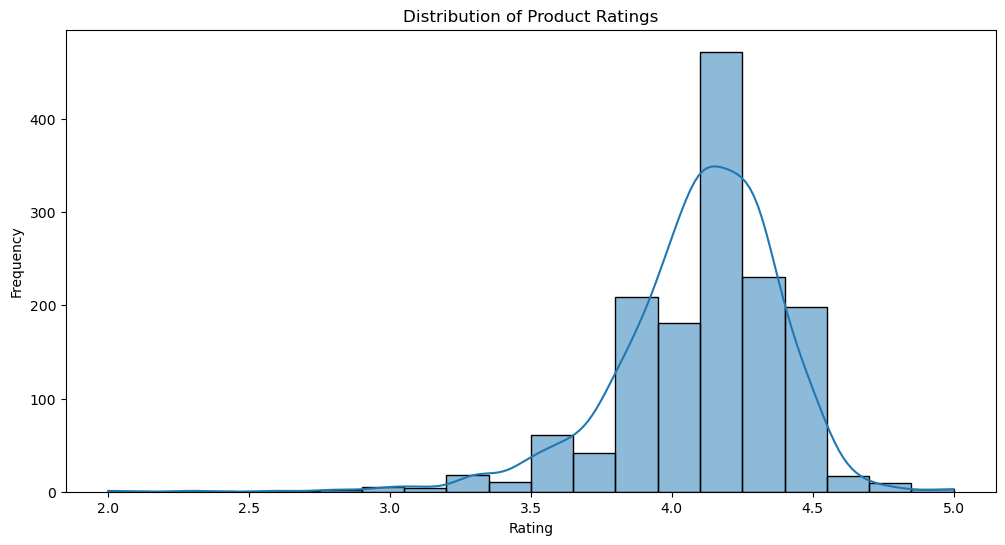

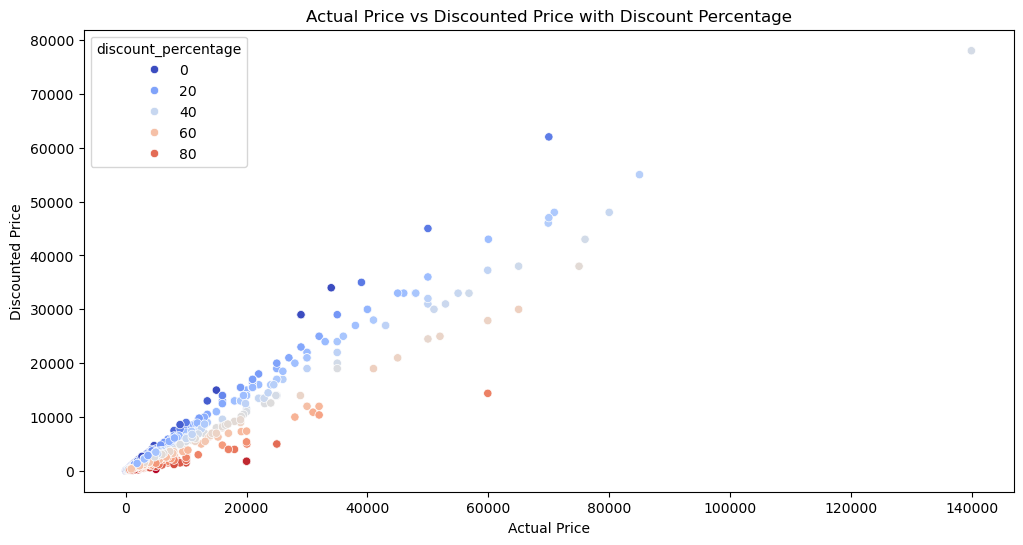

Top 10 Rated Products:
                                            product_name  rating
324   REDTECH USB-C to Lightning Cable 3.3FT, [Apple...     5.0
174   Syncwire LTG to USB Cable for Fast Charging Co...     5.0
775   Amazon Basics Wireless Mouse | 2.4 GHz Connect...     5.0
1145  Swiffer Instant Electric Water Heater Faucet T...     4.8
1201  Oratech Coffee Frother electric, milk frother ...     4.8
1299  Instant Pot Air Fryer, Vortex 2QT, Touch Contr...     4.8
249   Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...     4.7
1388  Campfire Spring Chef Prolix Instant Portable W...     4.7
1226  Zuvexa USB Rechargeable Electric Foam Maker - ...     4.7
459   Spigen EZ Fit Tempered Glass Screen Protector ...     4.7


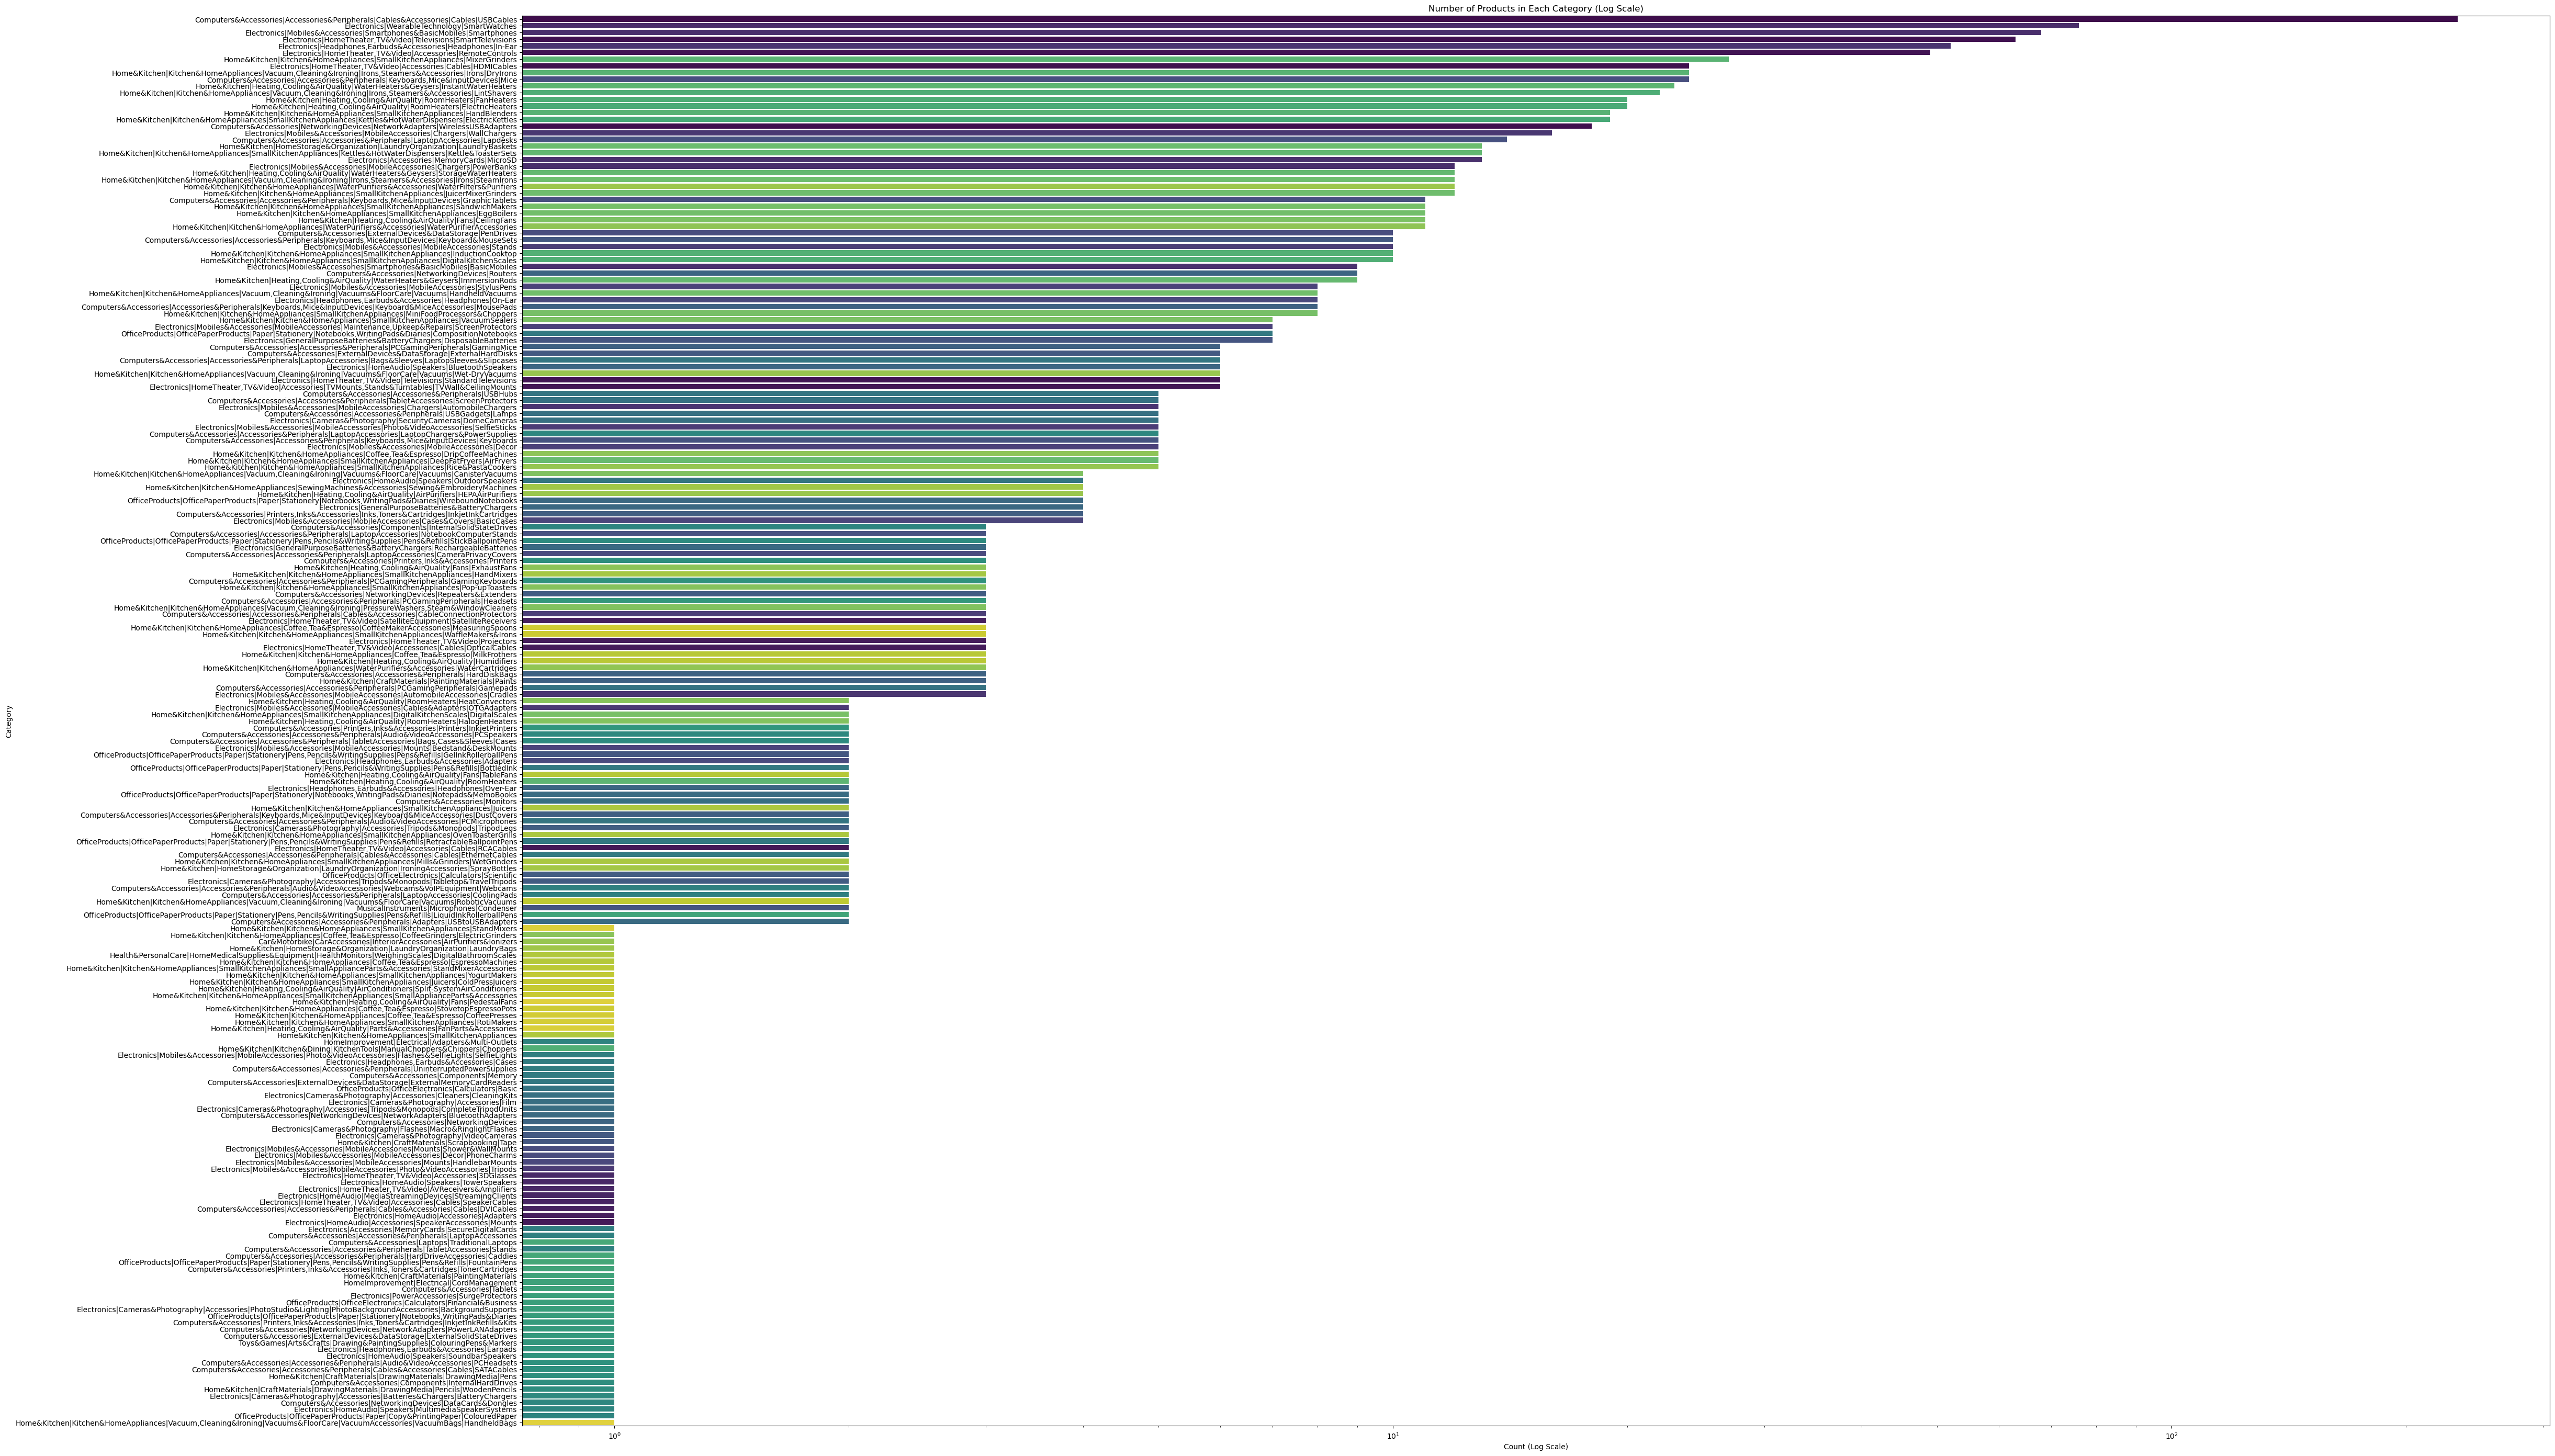

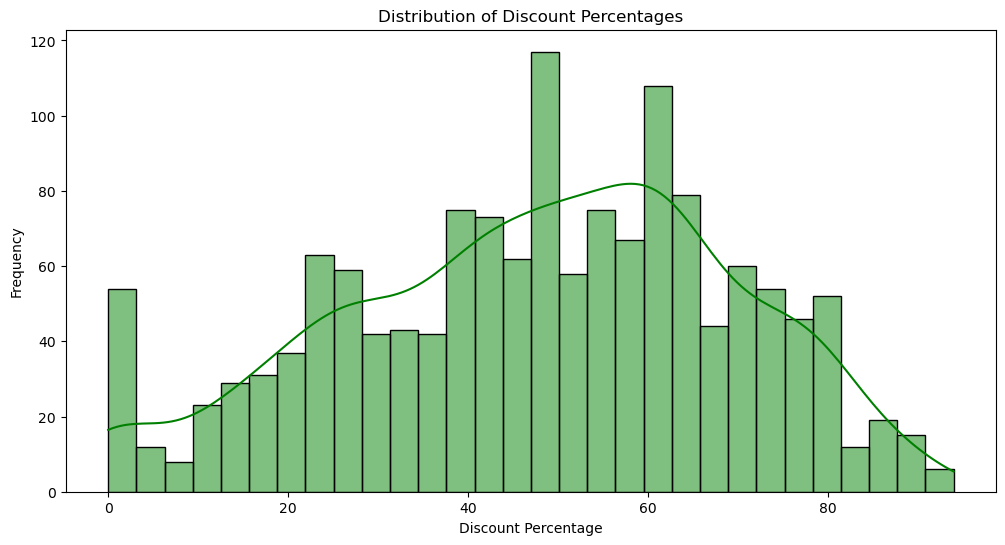

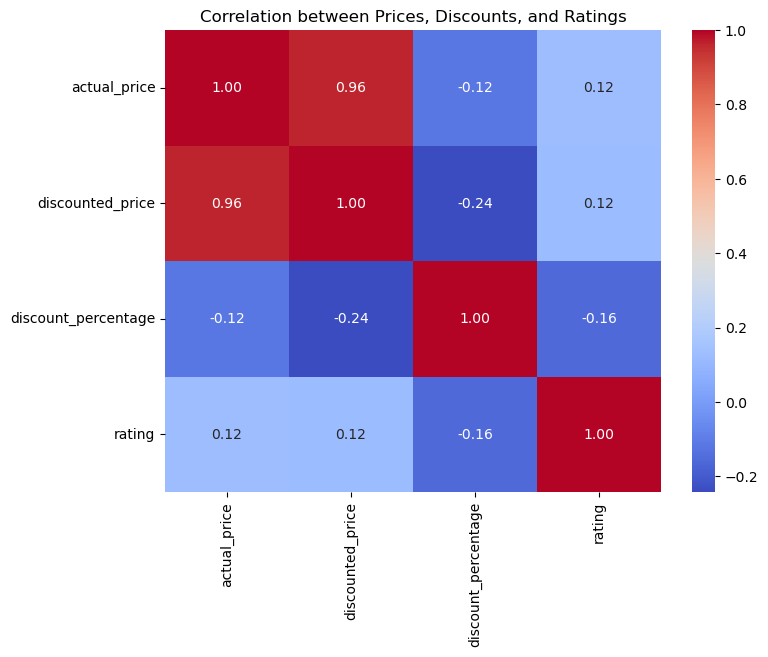

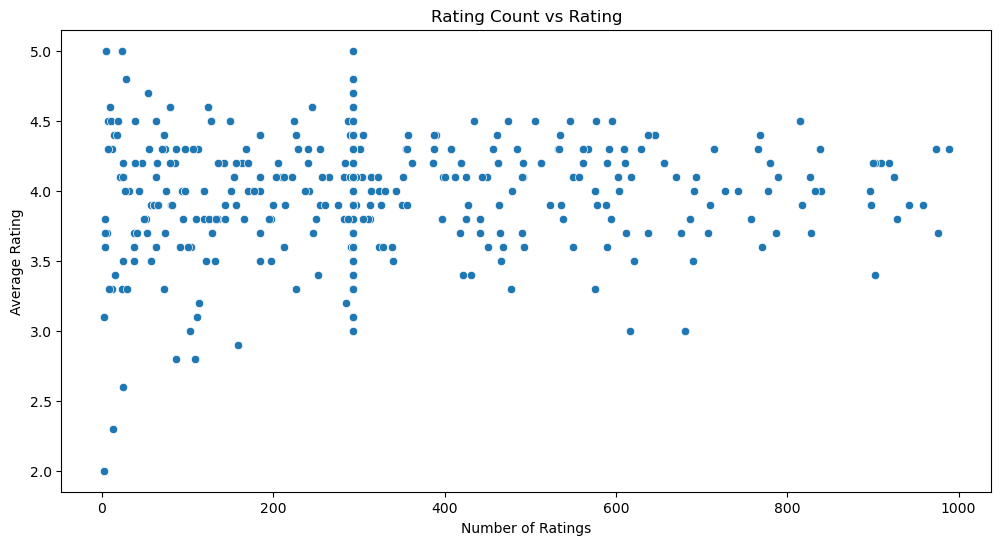

Top 10 Most Popular Products by Rating Count:
                                            product_name  rating_count
1279  Eureka Forbes car Vac 100 Watts Powerful Sucti...         992.0
750        Eveready Red 1012 AAA Batteries - Pack of 10         989.0
1059  Pigeon 1.5 litre Hot Kettle and Stainless Stee...         976.0
823   Zoul USB C 60W Fast Charging 3A 6ft/2M Long Ty...         974.0
32    Zoul USB C 60W Fast Charging 3A 6ft/2M Long Ty...         974.0
151   Zoul USB Type C Fast Charging 3A Nylon Braided...         974.0
1272  Bajaj New Shakti Neo Plus 15 Litre 4 Star Rate...         959.0
1259  Hindware Atlantic Xceed 5L 3kW Instant Water H...         942.0
214   Crypo™ Universal Remote Compatible with Tata S...         928.0
1262  iBELL Castor CTEK15L Premium 1.5 Litre Stainle...         925.0


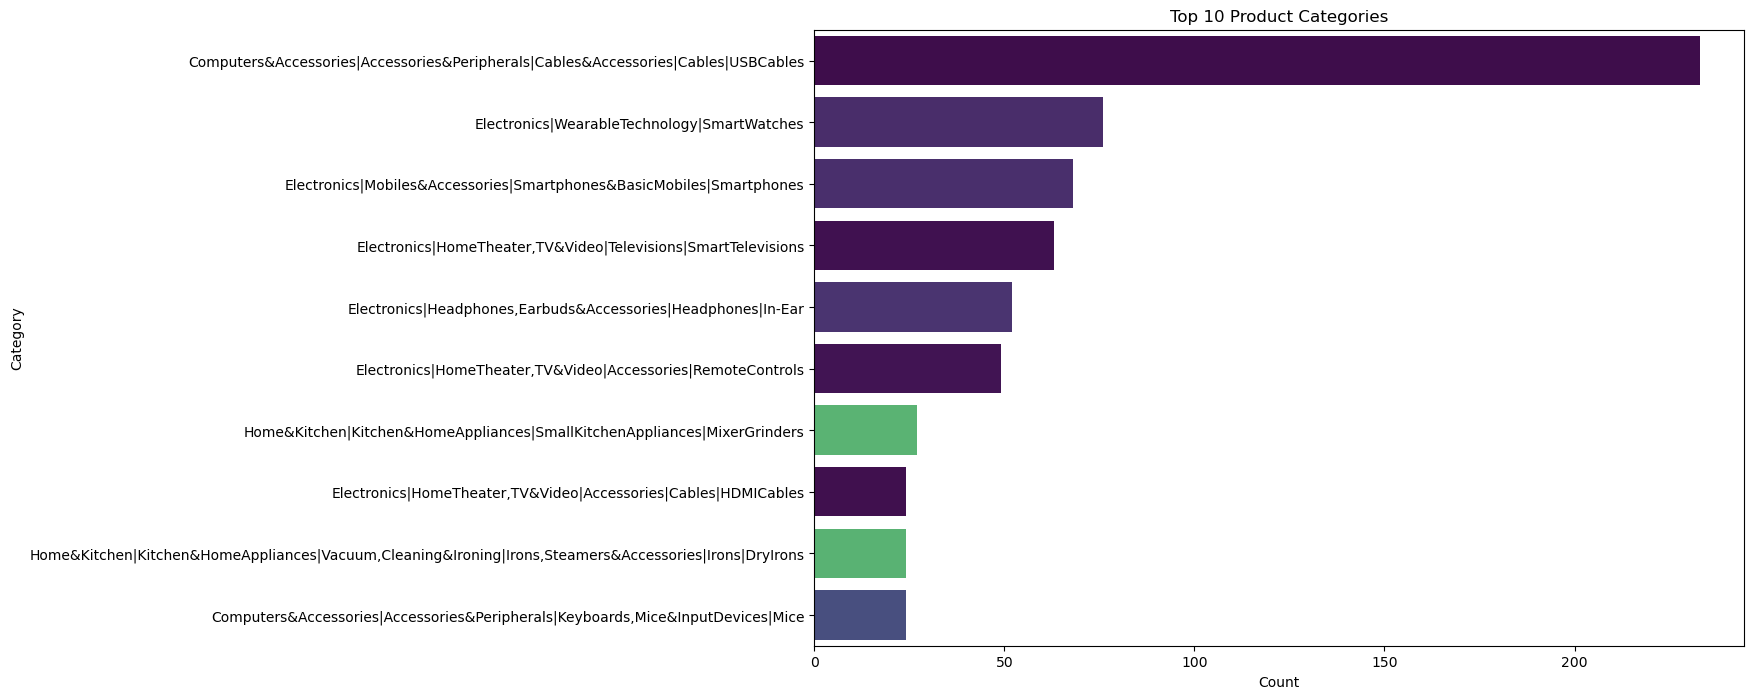

In [31]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
data = pd.read_csv("amazon.csv")

# Data Cleaning

# Remove ₹ and , from price columns and convert to float
data['discounted_price'] = data['discounted_price'].str.replace('₹', '').str.replace(',', '').astype(float)
data['actual_price'] = data['actual_price'].str.replace('₹', '').str.replace(',', '').astype(float)

# Remove % sign from discount_percentage and convert to float
data['discount_percentage'] = data['discount_percentage'].str.replace('%', '').astype(float)

# Convert 'rating' and 'rating_count' to numeric values (handling errors)
data['rating'] = pd.to_numeric(data['rating'], errors='coerce')
data['rating_count'] = pd.to_numeric(data['rating_count'], errors='coerce')

# Fill missing values in 'rating_count' without inplace to avoid chained assignment warning
data['rating_count'] = data['rating_count'].fillna(data['rating_count'].median())

# Display basic information after cleaning
print(data.info())
print(data.describe())

# 1. Distribution of Ratings
plt.figure(figsize=(12, 6))
sns.histplot(data['rating'], bins=20, kde=True)
plt.title('Distribution of Product Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

# 2. Price vs Discount Analysis
plt.figure(figsize=(12, 6))
sns.scatterplot(x='actual_price', y='discounted_price', hue='discount_percentage', data=data, palette='coolwarm')
plt.title('Actual Price vs Discounted Price with Discount Percentage')
plt.xlabel('Actual Price')
plt.ylabel('Discounted Price')
plt.show()

# 3. Top 10 Rated Products
top_rated = data[['product_name', 'rating']].sort_values(by='rating', ascending=False).head(10)
print("Top 10 Rated Products:\n", top_rated)

# 4. Category-wise Product Count (fixed the hue warning)
# Show the plot
plt.show()

# Plot the category-wise product count with log scale for better clarity
plt.figure(figsize=(50, 35))

# Create the count plot, set 'hue' to the same variable used in 'y' and disable the legend
ax = sns.countplot(y='category', data=data, order=data['category'].value_counts().index, hue='category', palette='viridis', legend=False)

# Set x-axis to log scale for better comparison across large differences
ax.set_xscale("log")

# Add titles and labels
plt.title('Number of Products in Each Category (Log Scale)')
plt.ylabel('Category')
plt.xlabel('Count (Log Scale)')
plt.show()



# 5. Distribution of Discounts
plt.figure(figsize=(12, 6))
sns.histplot(data['discount_percentage'], bins=30, kde=True, color='green')
plt.title('Distribution of Discount Percentages')
plt.xlabel('Discount Percentage')
plt.ylabel('Frequency')
plt.show()

# 6. Correlation Analysis
correlation_matrix = data[['actual_price', 'discounted_price', 'discount_percentage', 'rating']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation between Prices, Discounts, and Ratings')
plt.show()

# 7. Rating Count vs Rating
plt.figure(figsize=(12, 6))
sns.scatterplot(x='rating_count', y='rating', data=data)
plt.title('Rating Count vs Rating')
plt.xlabel('Number of Ratings')
plt.ylabel('Average Rating')
plt.show()

# 8. Top 10 Most Popular Products by Rating Count
top_popular = data[['product_name', 'rating_count']].sort_values(by='rating_count', ascending=False).head(10)
print("Top 10 Most Popular Products by Rating Count:\n", top_popular)

# Limit to top 10 categories
top_n = 10
plt.figure(figsize=(12, 8))  # Adjust plot size for better visibility

# Set 'hue' to 'category' and use legend=False to avoid future warnings
sns.countplot(y='category', data=data, 
              order=data['category'].value_counts().index[:top_n], 
              hue='category', palette='viridis', legend=False)

plt.title(f'Top {top_n} Product Categories')
plt.ylabel('Category')
plt.xlabel('Count')
plt.show()


